In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import auc, roc_curve
from statannotations.Annotator import Annotator

project_dir = Path.cwd().parents[1]
sys.path.append(str(project_dir))

print(f"Project directory: {project_dir}")

output_dir = project_dir / "output/"

root_dir_scores = output_dir / "scores"
root_dir_admission = output_dir / "Admission_model"
root_dir_full = output_dir / "Full_model"

SMALL_SIZE = 20
MEDIUM_SIZE = 25
BIGGER_SIZE = 30
plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title


Project directory: /home/nnieto/Nico/MODS_project/CULPRIT_project/MACRO_experiments


# Models AUC

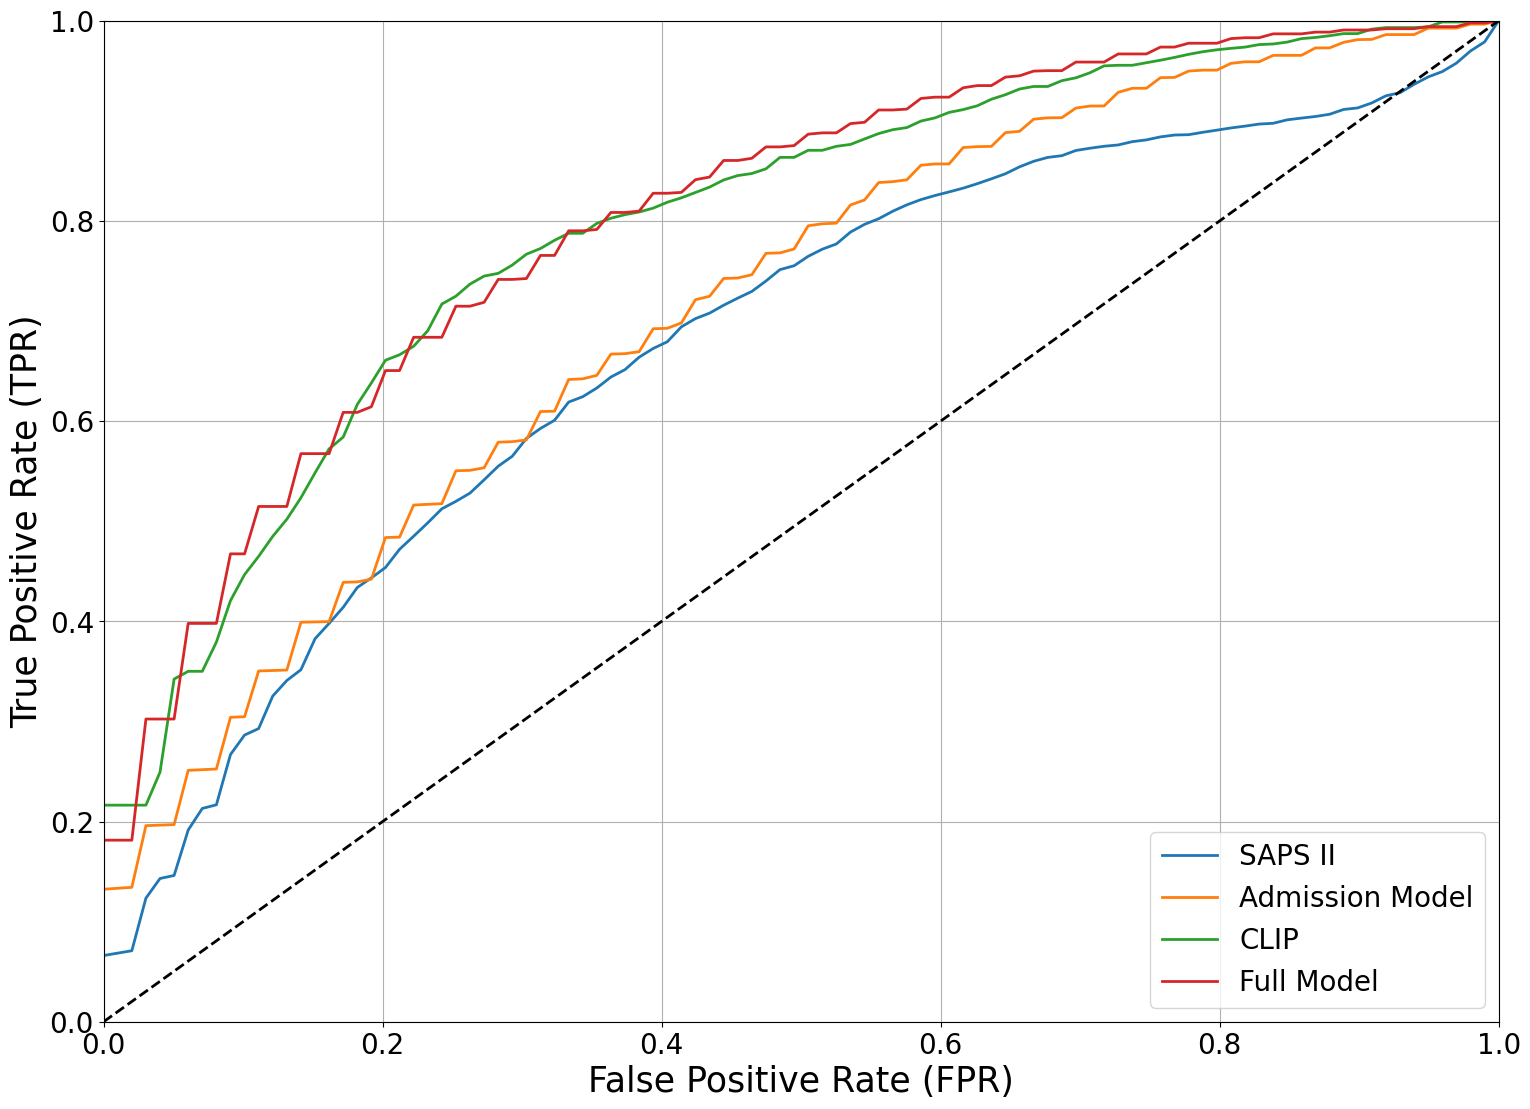

In [12]:


num_folds = 100
method_names = [
    ["SAPS", root_dir_scores],
    ["Admission", root_dir_admission],
    ["CLIP", root_dir_scores],
    ["Full", root_dir_full],
]

all_fpr = np.linspace(0, 1, 100)
plt.figure(figsize=(18, 13))

for method_name, root_dir in method_names:
    y_pred_all = pd.read_csv(root_dir / (method_name + "_predictions.csv"), index_col=0)
    y_true_all = pd.read_csv(root_dir / (method_name + "_y_true.csv"), index_col=0)
    # Initialize arrays to store accumulated TPR and FPR values
    mean_tpr = 0

    for fold in y_pred_all.columns:
        y_pred = y_pred_all.loc[:, fold]
        y_pred.dropna(inplace=True)
        y_true = y_true_all.loc[:, str(fold)]
        y_true.dropna(inplace=True)

        # Calculate ROC curve for the current fold
        fpr, tpr, _ = roc_curve(y_true, y_pred)

        # Interpolate the TPR values to match the all_fpr values
        mean_tpr += np.interp(all_fpr, fpr, tpr)

    # Calculate the mean TPR across all folds for the current method
    mean_tpr /= num_folds

    # Calculate the AUC for the average ROC curve of the current method
    mean_auc = auc(all_fpr, mean_tpr)
    # Plot the average ROC curve for the current method
    plt.plot(all_fpr, mean_tpr, lw=2, label=f"{method_name} (AUC = {mean_auc:.2f})")


# Plot the chance level line
plt.plot([0, 1], [0, 1], "k--", lw=2, label="Chance Level")

# Add labels and legend
# plt.title('Average ROC Curve across Folds')
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(["SAPS II", "Admission Model", "CLIP", "Full Model"], loc="lower right")
plt.grid(True)
plt.xlim([0, 1])
plt.ylim([0, 1])
SMALL_SIZE = 20
MEDIUM_SIZE = 25
BIGGER_SIZE = 30
plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title


# Show the plot
plt.show()

# Admission on CULPRIT

In [ ]:
root_dir_admission = output_dir / "Admission_model"
root_dir_full = output_dir / "Full_model"


results_admission = pd.read_csv(
    root_dir_admission / "Admission_random_remove.csv", index_col=0
)
results_admission = results_admission[results_admission["Thresholds"] == 0.5]
results_admission = results_admission[
    results_admission["Number of Removed Features"] == 0
]


results_24hs = pd.read_csv(root_dir_full / "Full_random_remove.csv", index_col=0)
results_24hs = results_24hs[results_24hs["Thresholds"] == 0.5]
results_24hs = results_24hs[results_24hs["Number of Removed Features"] == 0]


results_df = pd.concat([results_admission, results_24hs])

results_true_label = results_df[results_df["Random State"] == False]


models_to_plot = [
    "Full Model",
    "Admission",
    #   "24hs",
    #   "SAPS_SCORE",
    #   "CLIP_SCORE",
]

metrics = ["Balanced ACC", "AUC", "F1", "Specificity", "Sensitivity"]

for model in models_to_plot:
    print(model)
    for metric in metrics:
        results_mean = round(
            results_true_label[results_true_label["Model"] == model][metric].mean(), 3
        )
        results_std = round(
            results_true_label[results_true_label["Model"] == model][metric].std(), 3
        )
        confidence_interval = stats.t.interval(
            0.95,
            len(results_true_label[results_true_label["Model"] == model][metric]) - 1,
            loc=results_mean,
            scale=results_std,
        )

        print(
            metric
            + ": "
            + str(results_mean)
            + " ["
            + str(round(confidence_interval[0], 3))
            + "/"
            + str(round(confidence_interval[1], 3))
            + "]"
        )


Full Model
Balanced ACC: 0.712 [0.603/0.821]
AUC: 0.802 [0.697/0.907]
F1: 0.64 [0.489/0.791]
Specificity: 0.824 [0.701/0.947]
Sensitivity: 0.601 [0.414/0.788]
Admission
Balanced ACC: 0.646 [0.539/0.753]
AUC: 0.712 [0.591/0.833]
F1: 0.617 [0.486/0.748]
Specificity: 0.69 [0.545/0.835]
Sensitivity: 0.602 [0.431/0.773]


# Random performance

p-value annotation legend:
      ns: 1.00e-03 < p <= 1.00e+00
*p<0.001: p <= 1.00e-03

Full Model_False vs. Full Model_True: Mann-Whitney-Wilcoxon test two-sided, P_val:3.516e-60 U_stat=9.956e+04
Admission_False vs. Admission_True: Mann-Whitney-Wilcoxon test two-sided, P_val:7.106e-53 U_stat=9.636e+04


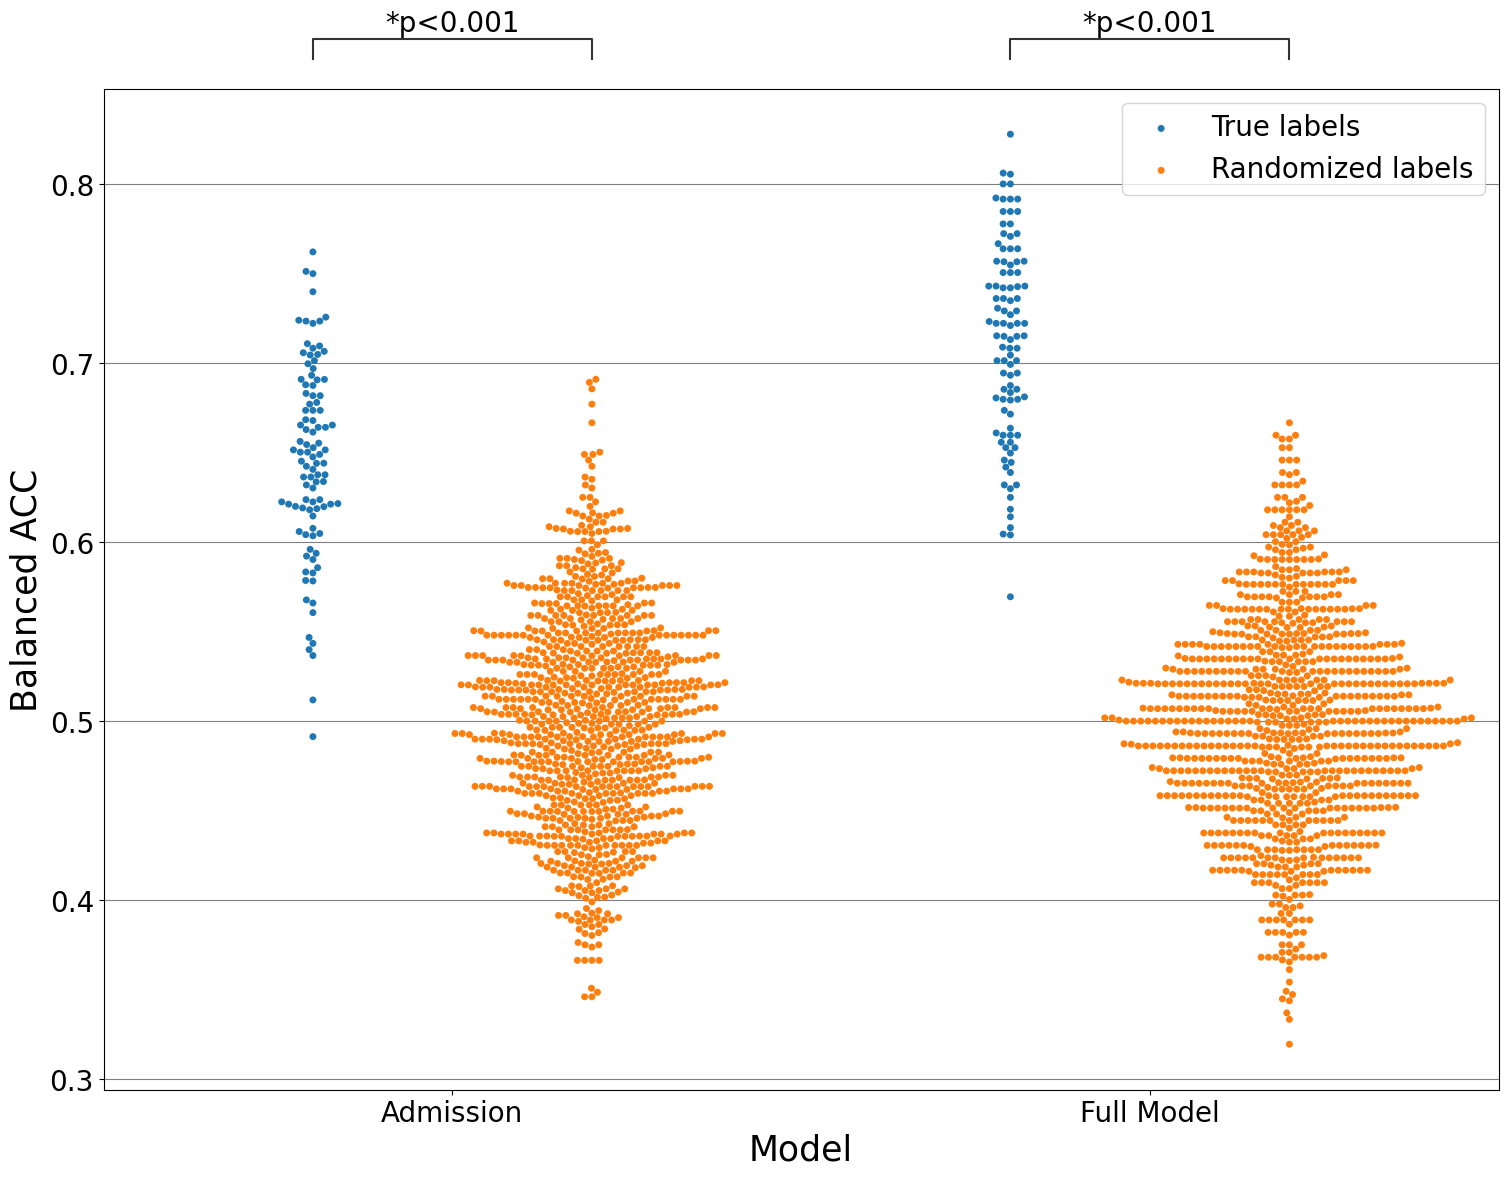

In [ ]:
# Load OPTUNA DATA

root_dir_admission = output_dir / "Admission_model"
root_dir_full = output_dir / "Full_model"

results_full_permuted = pd.read_csv(root_dir_full / "Full_permutation_test.csv")
results_full_permuted = results_full_permuted[
    results_full_permuted["Thresholds"] == 0.5
]
results_full_permuted = results_full_permuted[
    results_full_permuted["Number of Removed Features"] == 0
]
results_full_permuted = results_full_permuted.drop_duplicates(
    subset=["Fold", "Random Permutation Number"], keep="first"
)
results_full_permuted["Model"] = "Full Model"


results_full = pd.read_csv(root_dir_full / "Full_direct_remove.csv", index_col=0)
results_full = results_full[results_full["Thresholds"] == 0.5]
results_full = results_full[results_full["Number of Removed Features"] == 0]
results_full["Random State"] = False


results_admission_permuted = pd.read_csv(root_dir_admission / "Admission_permutation_test.csv")
results_admission_permuted = results_admission_permuted[
    results_admission_permuted["Thresholds"] == 0.5
]


results_admission = pd.read_csv(
    root_dir_admission / "Admission_direct_remove.csv", index_col=0
)

results_admission = results_admission[results_admission["Thresholds"] == 0.5]
results_admission = results_admission[
    results_admission["Number of Removed Features"] == 0
]
results_admission["Random State"] = False

models_to_plot = [
    "Admission",
    "Full Model",
]

res = pd.concat(
    [results_admission, results_admission_permuted, results_full, results_full_permuted]
)
metric_to_plot = "Balanced ACC"

fig, ax = plt.subplots(1, 1, figsize=[18, 13])

sns.swarmplot(
    data=res,
    x="Model",
    y=metric_to_plot,
    dodge=True,
    hue="Random State",
    ax=ax,
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[: models_to_plot.__len__()], labels[: models_to_plot.__len__()])
ax.legend(["True labels", "Randomized labels"])

# Comparisons for statistical test
box_list = [
    (("Admission", True), ("Admission", False)),
    (("Full Model", True), ("Full Model", False)),
]
plt.grid(alpha=0.5, axis="y", c="black")


annotator = Annotator(ax, box_list, data=res, x="Model", y=metric_to_plot, hue="Random State")
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside',pvalue_thresholds=[[1, "ns"], [0.001, "*p<0.001"]])
annotator.apply_and_annotate()

plt.show()


# Missing value experiment Admission Model

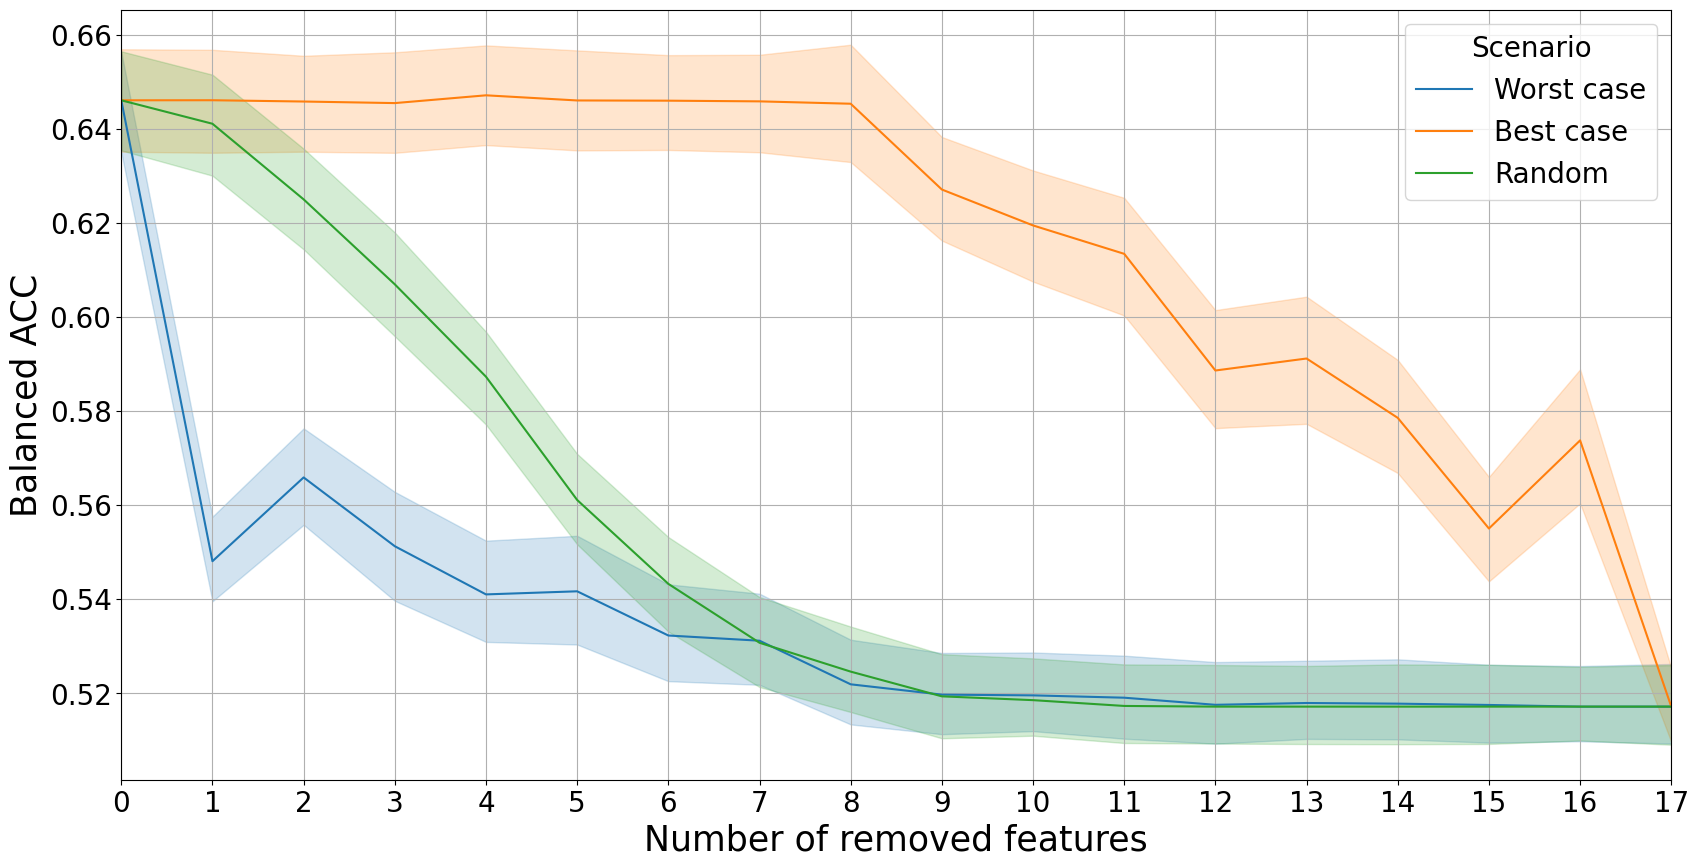

In [ ]:
root_dir_admission = output_dir / "Admission_model"

results_random = pd.read_csv(
    root_dir_admission / "Admission_random_remove.csv", index_col=0
)
results_random = results_random[results_random["Thresholds"] == 0.5]
results_random["Scenario"] = "Random"

results_direct = pd.read_csv(
    root_dir_admission / "Admission_direct_remove.csv", index_col=0
)
results_direct = results_direct[results_direct["Thresholds"] == 0.5]
results_direct["Scenario"] = "Worst case"

results_inverse = pd.read_csv(
    root_dir_admission / "Admission_inverse_remove.csv", index_col=0
)

results_inverse = results_inverse[results_inverse["Thresholds"] == 0.5]
results_inverse["Scenario"] = "Best case"

# Reset index to avoid duplicates
results_random.reset_index(drop=True, inplace=True)
results_direct.reset_index(drop=True, inplace=True)
results_inverse.reset_index(drop=True, inplace=True)
results_mv = pd.concat(
    [results_direct, results_inverse, results_random], ignore_index=True
)


fig, ax = plt.subplots(1, 1, figsize=[20, 10])
metric_to_plot = "Balanced ACC"
results_mv_to_plot = results_mv[results_mv["Model"] == "Admission"]

sns.lineplot(
    data=results_mv_to_plot,
    x="Number of Removed Features",
    y=metric_to_plot,
    hue="Scenario",
    ax=ax,
)
plt.grid()
plt.xlim(0, 17)
plt.xlabel("Number of removed features")
custom_ticks = np.arange(0, 18, 1)  # Range from 0 to 1 with step of 0.1
plt.xticks(custom_ticks)
# plt.title("Missing values impact in 24hs Model")
plt.show()

# Missing value experiment Full Model

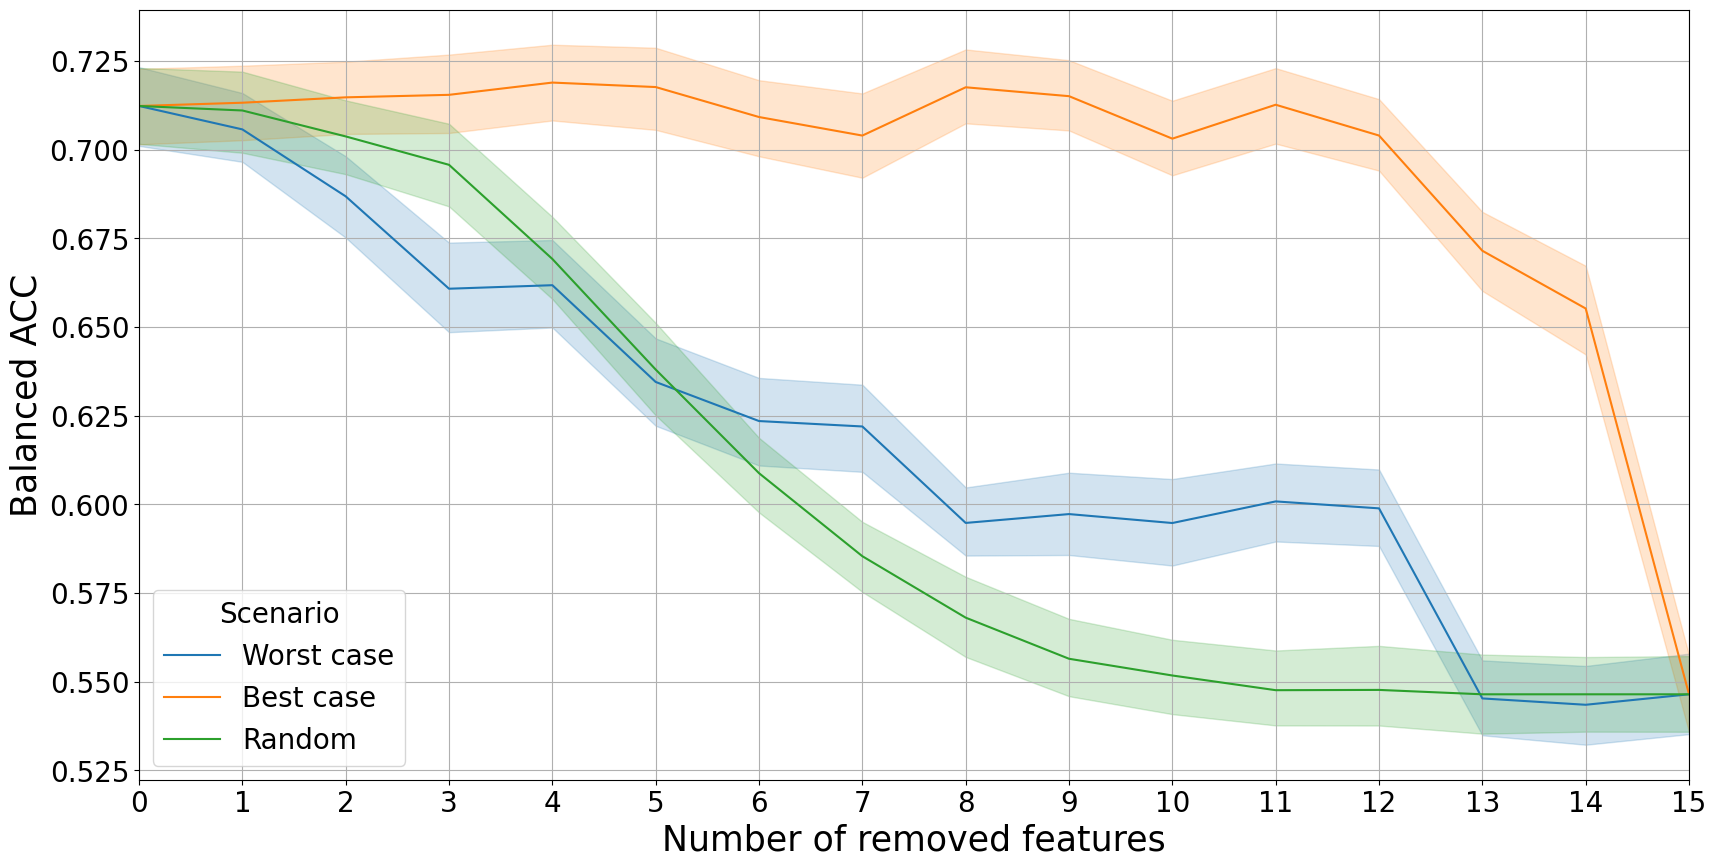

In [ ]:
root_dir_full = output_dir / "Full_model"

results_random = pd.read_csv(root_dir_full / "Full_random_remove.csv", index_col=0)
results_random = results_random[results_random["Thresholds"] == 0.5]
results_random["Scenario"] = "Random"

results_direct = pd.read_csv(root_dir_full / "Full_direct_remove.csv", index_col=0)
results_direct = results_direct[results_direct["Thresholds"] == 0.5]
results_direct["Scenario"] = "Worst case"

results_inverse = pd.read_csv(root_dir_full / "Full_inverse_remove.csv", index_col=0)

results_inverse = results_inverse[results_inverse["Thresholds"] == 0.5]
results_inverse["Scenario"] = "Best case"
# Reset index to avoid duplicates
results_random.reset_index(drop=True, inplace=True)
results_direct.reset_index(drop=True, inplace=True)
results_inverse.reset_index(drop=True, inplace=True)
results_mv = pd.concat(
    [results_direct, results_inverse, results_random], ignore_index=True
)


fig, ax = plt.subplots(1, 1, figsize=[20, 10])
metric_to_plot = "Balanced ACC"
results_mv_to_plot = results_mv[results_mv["Model"] == "Full Model"]

sns.lineplot(
    data=results_mv_to_plot,
    x="Number of Removed Features",
    y=metric_to_plot,
    hue="Scenario",
    ax=ax,
)
plt.grid()
plt.xlim(0, 15)
plt.xlabel("Number of removed features")
custom_ticks = np.arange(0, 16, 1)  # Range from 0 to 1 with step of 0.1
plt.xticks(custom_ticks)
# plt.title("Missing values impact in 24hs Model")
plt.show()

# CaordShock Score 

In [ ]:
root_dir_scores = output_dir / "scores"

results_CardShock = pd.read_csv(root_dir_scores / "CardShock.csv", index_col=0)
results_CardShock = results_CardShock[
    results_CardShock["Number of Removed Features"] == 0
]
results_CardShock = results_CardShock[results_CardShock["Thresholds"] == 0.5]
results_CardShock.drop(
    columns=[
        "Fold",
        "Random State",
        "Random Permutation Number",
        "Thresholds",
        "Number of Removed Features",
        "Recall",
    ],
    inplace=True,
)

results_true_label = pd.concat([results_CardShock])


models_to_plot = [
    "CardShock_Score_test",
]

metrics = ["Balanced ACC", "AUC", "F1", "Specificity", "Sensitivity"]

for model in models_to_plot:
    print(model)
    for metric in metrics:
        results_mean = round(
            results_true_label[results_true_label["Model"] == model][metric].mean(), 3
        )
        results_std = round(
            results_true_label[results_true_label["Model"] == model][metric].std(), 3
        )
        confidence_interval = stats.t.interval(
            0.95,
            len(results_true_label[results_true_label["Model"] == model][metric]) - 1,
            loc=results_mean,
            scale=results_std,
        )

        print(
            metric
            + ": "
            + str(results_mean)
            + " ["
            + str(round(confidence_interval[0], 3))
            + "/"
            + str(round(confidence_interval[1], 3))
            + "]"
        )


CardShock_Score_test
Balanced ACC: 0.567 [0.373/0.761]
AUC: 0.694 [0.418/0.97]
F1: 0.341 [-0.115/0.797]
Specificity: 0.807 [0.454/1.16]
Sensitivity: 0.328 [-0.196/0.852]


# Admission model performance on eICU dataset

In [ ]:
results_dir = "/home/nnieto/Nico/MODS_project/CULPRIT_project/output/review_1/eICU/admission_model/"  # noqa

results_admission = pd.read_csv(
    results_dir + "Admission_performance_CULPRIT_eICU.csv", index_col=0
)
results_admission = results_admission[
    results_admission["Number of Removed Features"] == 0
]
results_admission = results_admission[results_admission["Thresholds"] == 0.5]
results_admission.drop(
    columns=[
        "Fold",
        "Random State",
        "Random Permutation Number",
        "Thresholds",
        "Number of Removed Features",
        "Recall",
    ],
    inplace=True,
)

results_true_label = pd.concat([results_admission])


models_to_plot = ["Admission Train (CULPRIT)", "Admission Test (eICU)"]

metrics = ["Balanced ACC", "AUC", "F1", "Specificity", "Sensitivity"]

for model in models_to_plot:
    print(model)
    for metric in metrics:
        results_mean = round(
            results_true_label[results_true_label["Model"] == model][metric].mean(), 3
        )
        results_std = round(
            results_true_label[results_true_label["Model"] == model][metric].std(), 3
        )

        print(metric + ": " + str(results_mean))


Admission Train (CULPRIT)
Balanced ACC: 0.712
AUC: 0.8
F1: 0.687
Specificity: 0.762
Sensitivity: 0.662
Admission Test (eICU)
Balanced ACC: 0.605
AUC: 0.63
F1: 0.523
Specificity: 0.678
Sensitivity: 0.531


# Full model performance on eICU dataset

In [ ]:
results_dir = (
    "/home/nnieto/Nico/MODS_project/CULPRIT_project/output/review_1/eICU/full_model/"  # noqa
)

results = pd.read_csv(results_dir + "Full_performance_CULPRIT_eICU.csv", index_col=0)
results.drop(
    columns=[
        "Fold",
        "Random State",
        "Random Permutation Number",
        "Thresholds",
        "Number of Removed Features",
        "Recall",
    ],
    inplace=True,
)

results_true_label = pd.concat([results])


models_to_plot = ["Full Train (CULPRIT)", "Full test (eICU)"]

metrics = ["Balanced ACC", "AUC", "F1", "Specificity", "Sensitivity"]

for model in models_to_plot:
    print(model)
    for metric in metrics:
        results_mean = round(
            results_true_label[results_true_label["Model"] == model][metric].mean(), 3
        )
        results_std = round(
            results_true_label[results_true_label["Model"] == model][metric].std(), 3
        )

        print(metric + ": " + str(results_mean))


Full Train (CULPRIT)
Balanced ACC: 0.892
AUC: 0.952
F1: 0.872
Specificity: 0.942
Sensitivity: 0.843
Full test (eICU)
Balanced ACC: 0.636
AUC: 0.769
F1: 0.493
Specificity: 0.886
Sensitivity: 0.385


# LG Admission performance

In [3]:
results_dir = "/home/nnieto/Nico/MODS_project/CULPRIT_project/output/review_1/LG_compare/LG_with_scaler/"  # noqa

results = pd.read_csv(results_dir + "LG_complete_data_admission.csv", index_col=0)
results = results[results["Model"] == "LG_complete_admission_test"]
results = results[results["Number of Removed Features"] == 0]
results = results[results["Thresholds"] == 0.5]
results.drop(
    columns=[
        "Fold",
        "Random State",
        "Random Permutation Number",
        "Thresholds",
        "Number of Removed Features",
        "Recall",
    ],
    inplace=True,
)

results_true_label = pd.concat([results])


models_to_plot = [
    "LG_complete_admission_test",
]

metrics = ["Balanced ACC", "AUC", "F1", "Specificity", "Sensitivity"]

for model in models_to_plot:
    print(model)
    for metric in metrics:
        results_mean = round(
            results_true_label[results_true_label["Model"] == model][metric].mean(), 3
        )
        results_std = round(
            results_true_label[results_true_label["Model"] == model][metric].std(), 3
        )
        confidence_interval = stats.t.interval(
            0.95,
            len(results_true_label[results_true_label["Model"] == model][metric]) - 1,
            loc=results_mean,
            scale=results_std,
        )

        print(
            metric
            + ": "
            + str(results_mean)
            + " ["
            + str(round(confidence_interval[0], 3))
            + "/"
            + str(round(confidence_interval[1], 3))
            + "]"
        )


LG_complete_admission_test
Balanced ACC: 0.669 [0.554/0.784]
AUC: 0.734 [0.615/0.853]
F1: 0.624 [0.487/0.761]
Specificity: 0.737 [0.562/0.912]
Sensitivity: 0.601 [0.418/0.784]


shape y_true: (69, 100)
shape y_pred: (69, 100)


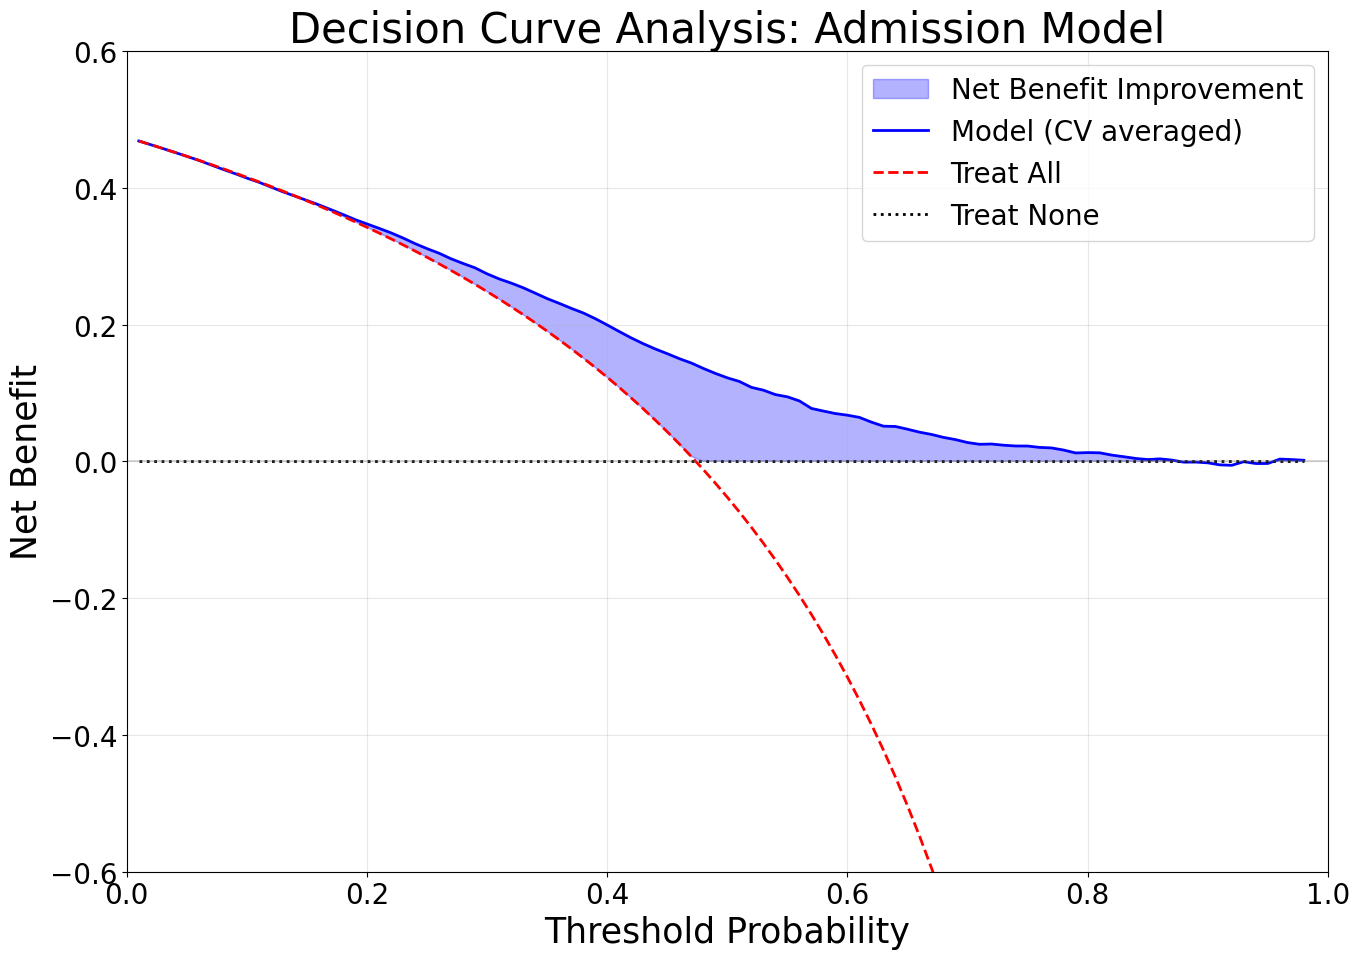

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def plot_dca(y_true, y_pred_probs, title, severity=None):
    """
    Decision Curve Analysis.
    
    Parameters:
    y_true: array of true labels (n_samples, n_folds)
    y_pred_probs: array of predicted probabilities (n_samples, n_folds)
    severity: array of severity labels (n_samples, n_folds) or None
    """
    
    n_folds = y_pred_probs.shape[1]
    thresholds = np.arange(0.01, 0.99, 0.01)
    
    # Store net benefit for each fold
    nb_all_folds = []
    
    for fold in range(n_folds):
        # Get predictions and true labels for this fold
        y_pred_fold = y_pred_probs[:, fold]
        y_true_fold = y_true[:, fold]
        
        # Apply severity filter if provided
        if severity is not None:
            severity_fold = severity[:, fold]
            mask = ~np.isnan(y_pred_fold) & ~np.isnan(severity_fold) & (severity_fold == 1)
        else:
            mask = ~np.isnan(y_pred_fold)
        
        y_pred_fold = y_pred_fold[mask]
        y_true_fold = y_true_fold[mask]
        
        n = len(y_true_fold)
        
        # Calculate net benefit for each threshold
        nb_fold = []
        for threshold in thresholds:
            y_pred = (y_pred_fold >= threshold).astype(int)
            tp = np.sum((y_true_fold == 1) & (y_pred == 1))
            fp = np.sum((y_true_fold == 0) & (y_pred == 1))
            nb = (tp / n) - (fp / n) * (threshold / (1 - threshold))
            nb_fold.append(nb)
        
        nb_all_folds.append(nb_fold)
    
    # Average net benefit across folds
    nb_model = np.mean(nb_all_folds, axis=0)
    
    # Treat all strategy (using all available data with severity filter)
    if severity is not None:
        severity_all = severity.flatten()
        y_true_all = y_true.flatten()
        mask = ~np.isnan(y_true_all) & ~np.isnan(severity_all) & (severity_all == 1)
        y_true_all = y_true_all[mask]
    else:
        y_true_all = y_true.flatten()
        y_true_all = y_true_all[~np.isnan(y_true_all)]
    
    n = len(y_true_all)
    n_pos = np.sum(y_true_all)
    n_neg = n - n_pos
    nb_all = [(n_pos / n) - (n_neg / n) * (t / (1 - t)) for t in thresholds]
    nb_none = np.zeros_like(thresholds)
    
    # Plot
    plt.figure(figsize=(14, 10))
    
    # Fill between model and the better of Treat All/Treat None
    # For each threshold, use max(nb_all, nb_none) as reference
    nb_best_benchmark = np.maximum(nb_all, nb_none)
    
    # Fill only where model is better than benchmark
    plt.fill_between(thresholds, nb_model, nb_best_benchmark, 
                     where=(nb_model >= nb_best_benchmark),
                     color='blue', alpha=0.3, interpolate=True,
                     label='Net Benefit Improvement')
    
    # Plot lines
    plt.plot(thresholds, nb_model, 'b-', linewidth=2, label='Model (CV averaged)')
    plt.plot(thresholds, nb_all, 'r--', linewidth=2, label='Treat All')
    plt.plot(thresholds, nb_none, 'k:', linewidth=2, label='Treat None')
    
    plt.xlabel('Threshold Probability')
    plt.ylabel('Net Benefit')
    if severity is not None:
        title += ' (Severity = 1)'
    plt.title(title)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    plt.xlim(0, 1)
    plt.ylim(-0.6, 0.6)
    plt.tight_layout()
    plt.show()

# Load data
y_true = pd.read_csv("/home/nnieto/Nico/MODS_project/CULPRIT_project/MACRO_experiments/output/Admission_model/Admission_y_true.csv", index_col=0).values
y_pred = pd.read_csv("/home/nnieto/Nico/MODS_project/CULPRIT_project/MACRO_experiments/output/Admission_model/Admission_predictions.csv", index_col=0).values
title = 'Decision Curve Analysis: Admission Model'

print("shape y_true: " + str(y_true.shape))
print("shape y_pred: " + str(y_pred.shape))

# Run DCA with severity filter
plot_dca(y_true, y_pred, title = title)

shape y_true(60, 100)
shape y_pred_probs(60, 100)


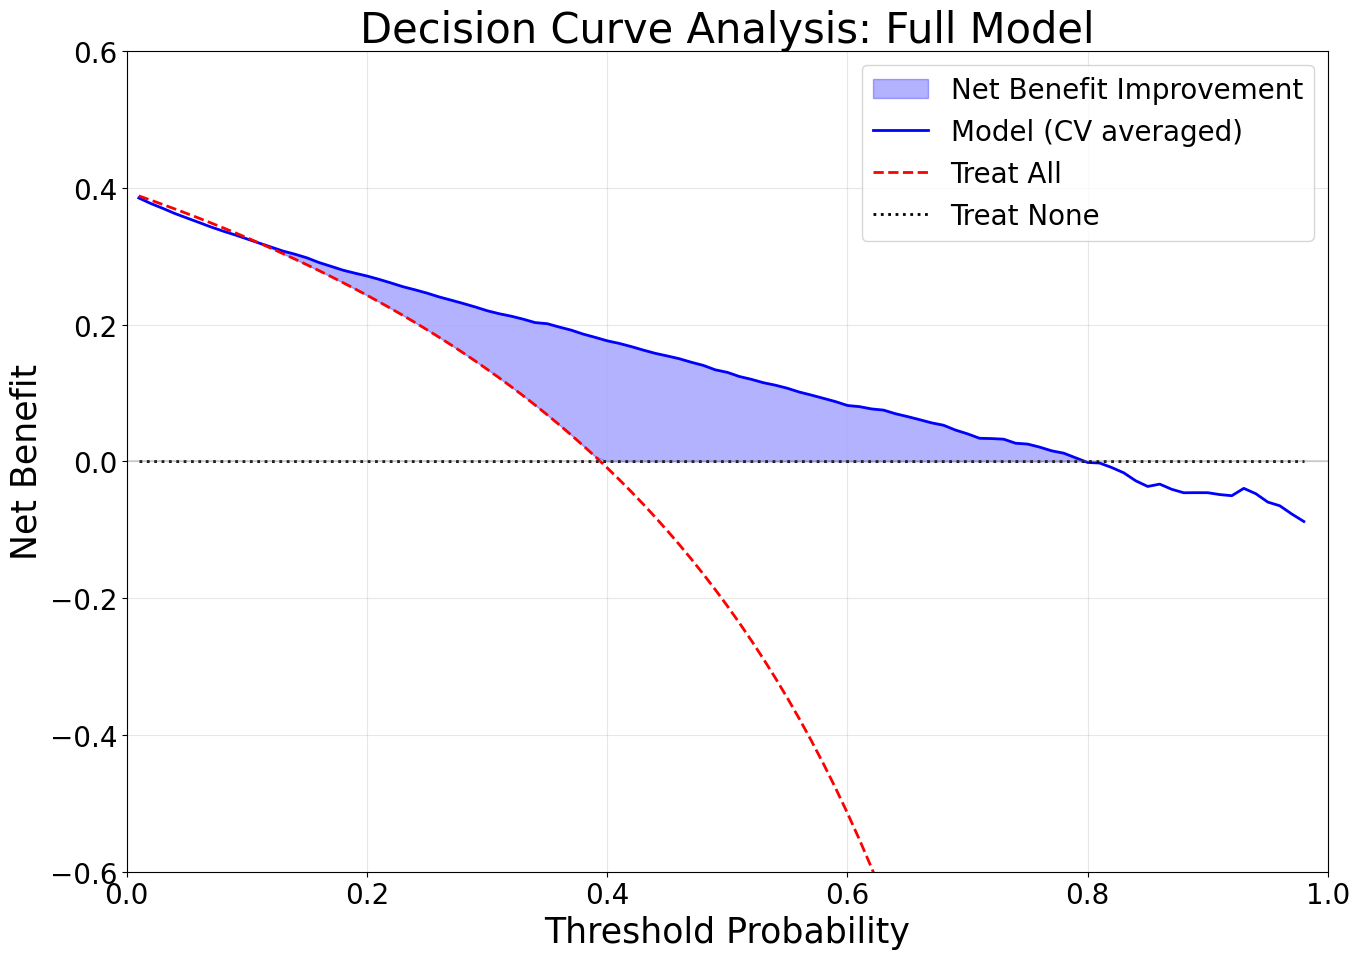

In [66]:
# Load data (index_col=0 removes the first column)
y_true = pd.read_csv("/home/nnieto/Nico/MODS_project/CULPRIT_project/MACRO_experiments/output/Full_model/Full_y_true.csv", index_col=0).values
y_pred_probs = pd.read_csv("/home/nnieto/Nico/MODS_project/CULPRIT_project/MACRO_experiments/output/Full_model/Full_predictions.csv", index_col=0).values

print("shape y_true"+ str(y_true.shape))
print("shape y_pred_probs"+ str(y_pred_probs.shape))
title = 'Decision Curve Analysis: Full Model'

# Run DCA
plot_dca(y_true, y_pred_probs, title)



shape y_true: (69, 100)
shape y_pred: (69, 100)


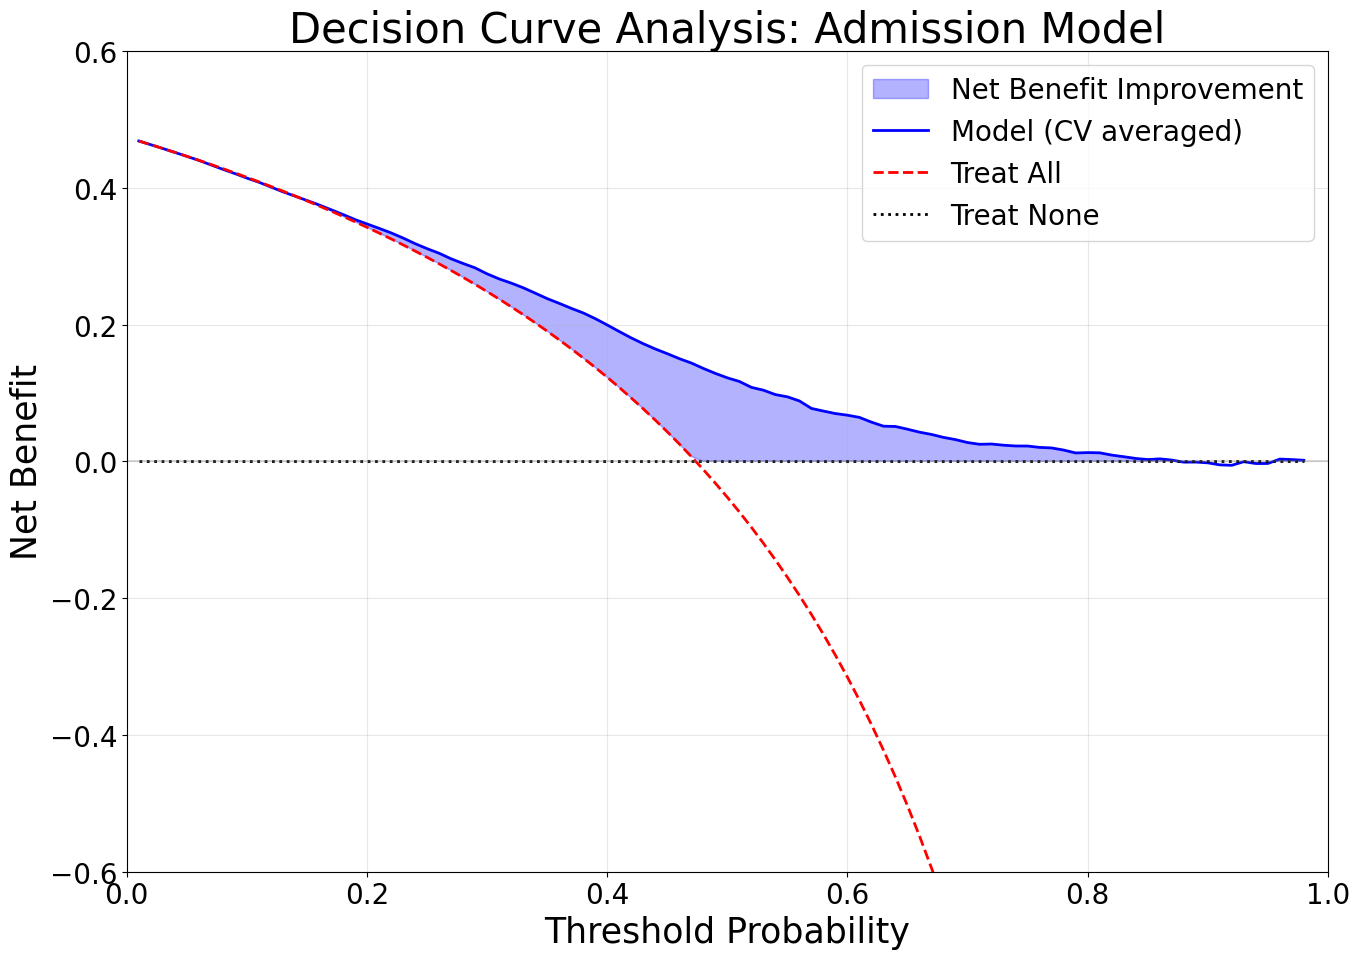

Model coefficients:
Weight (w): 0.1458
Intercept (b): -1.0713
Decision boundary: 7.3460

Predictions: 0 patients predicted as Expired (class 1)
Actually Expired: 65 patients

Confusion Matrix:
[[142   0]
 [ 65   0]]

Accuracy: 0.6860


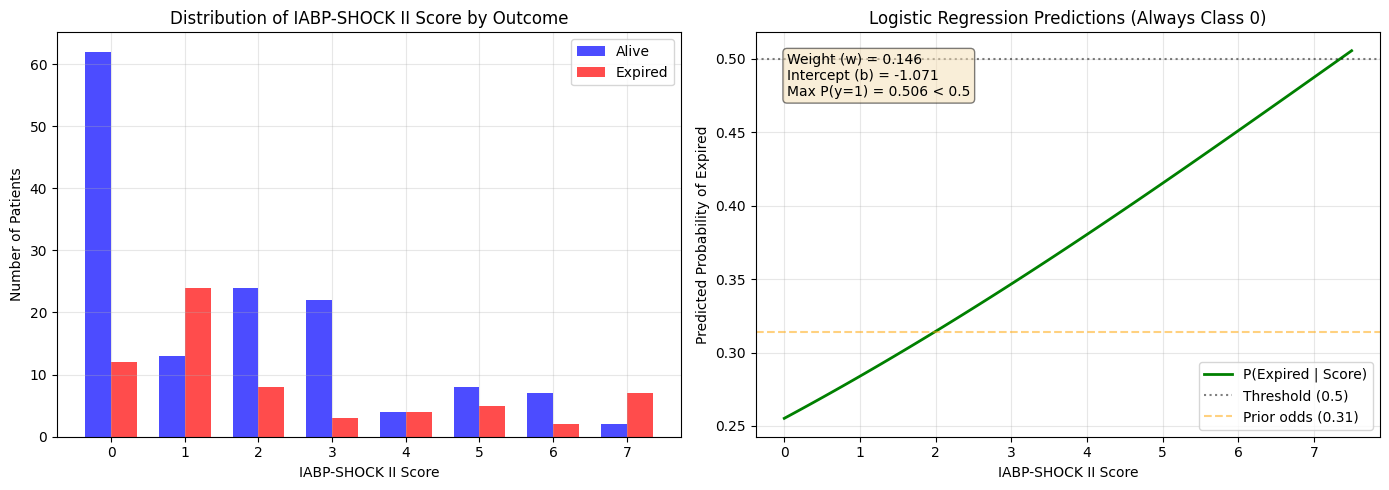


Effect of removing regularization (C=1000):
Weight: 0.1466
Intercept: -1.0728
Predictions: 0 patients predicted as Expired


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# Recreate your data from the table
scores = np.array([0, 1, 2, 3, 4, 5, 6, 7])
alive = np.array([62, 13, 24, 22, 4, 8, 7, 2])  # Approximate from image
expired = np.array([12, 24, 8, 3, 4, 5, 2, 7])   # Approximate from image

# Create full dataset
X = []
y = []
for score, n_alive, n_expired in zip(scores, alive, expired):
    X.extend([score] * (n_alive + n_expired))
    y.extend([0] * n_alive)  # 0 = Alive
    y.extend([1] * n_expired) # 1 = Expired

X = np.array(X).reshape(-1, 1)
y = np.array(y)

# Train model
model = LogisticRegression(C=1.0)  # Default regularization
model.fit(X, y)

# Get predictions
y_pred = model.predict(X)
y_prob = model.predict_proba(X)

# Results
print("Model coefficients:")
print(f"Weight (w): {model.coef_[0][0]:.4f}")
print(f"Intercept (b): {model.intercept_[0]:.4f}")
print(f"Decision boundary: {-model.intercept_[0]/model.coef_[0][0]:.4f}")
print(f"\nPredictions: {sum(y_pred)} patients predicted as Expired (class 1)")
print(f"Actually Expired: {sum(y)} patients")
print(f"\nConfusion Matrix:")
cm = confusion_matrix(y, y_pred)
print(cm)
print(f"\nAccuracy: {model.score(X, y):.4f}")

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribution by score
score_range = np.arange(0, 8)
bar_width = 0.35
ax1.bar(score_range - bar_width/2, alive, bar_width, label='Alive', color='blue', alpha=0.7)
ax1.bar(score_range + bar_width/2, expired, bar_width, label='Expired', color='red', alpha=0.7)
ax1.set_xlabel('IABP-SHOCK II Score')
ax1.set_ylabel('Number of Patients')
ax1.set_title('Distribution of IABP-SHOCK II Score by Outcome')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Predicted probabilities
X_test = np.linspace(0, 7.5, 100).reshape(-1, 1)
probs = model.predict_proba(X_test)[:, 1]

ax2.plot(X_test, probs, 'g-', linewidth=2, label='P(Expired | Score)')
ax2.axhline(0.5, color='black', linestyle=':', alpha=0.5, label='Threshold (0.5)')
ax2.axhline(sum(y)/len(y), color='orange', linestyle='--', alpha=0.5, 
            label=f'Prior odds ({sum(y)/len(y):.2f})')
ax2.set_xlabel('IABP-SHOCK II Score')
ax2.set_ylabel('Predicted Probability of Expired')
ax2.set_title('Logistic Regression Predictions (Always Class 0)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Add text box explaining
textstr = f'Weight (w) = {model.coef_[0][0]:.3f}\nIntercept (b) = {model.intercept_[0]:.3f}\nMax P(y=1) = {max(probs):.3f} < 0.5'
ax2.text(0.05, 0.95, textstr, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# Show why it fails with different regularization
print("\n" + "="*50)
print("Effect of removing regularization (C=1000):")
print("="*50)
model_no_reg = LogisticRegression(C=1000)  # Very little regularization
model_no_reg.fit(X, y)
print(f"Weight: {model_no_reg.coef_[0][0]:.4f}")
print(f"Intercept: {model_no_reg.intercept_[0]:.4f}")
print(f"Predictions: {sum(model_no_reg.predict(X))} patients predicted as Expired")